In [17]:
#K-Means is an example of Hard Clustering,where every point belongs only to one cluster.
import numpy as np
import matplotlib.pyplot as plt
from jax._src import clusters
from sklearn.datasets import make_blobs

In [18]:
X,Y=make_blobs(n_samples=500,n_features=2,centers=5,random_state=3)

In [19]:
print(X.shape)

(500, 2)


In [20]:
np.unique(Y) #We will not use Y in KMeans Because we need unlabeled data

array([0, 1, 2, 3, 4])

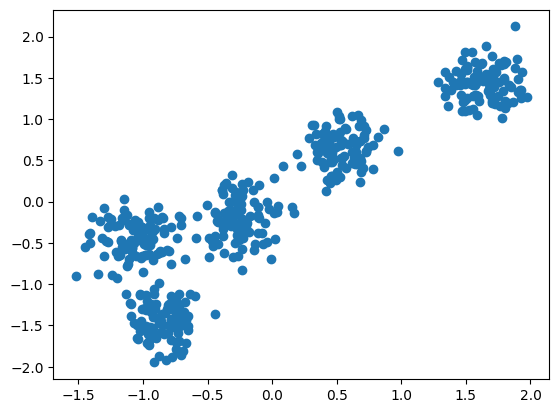

In [21]:
#Data Visualization
def normalize(X):
    u=X.mean(axis=0)
    std=X.std(axis=0)
    return (X-u)/std
X=normalize(X)
plt.scatter(X[:,0],X[:,1])
plt.show()

In [22]:
#Step-1 Init the k-centers for k-clusters
k=5
colors=["cyan","red","blue","green","orange"]
n_features=2

centroids={}

for i in range(k):

    center=2*(2*np.random.random((2,))-1)

    centroids[i]={
        'center':center,
        'color':colors[i],
        'points': []
    }

In [23]:
print(centroids)

{0: {'center': array([ 1.61729789, -0.20828567]), 'color': 'cyan', 'points': []}, 1: {'center': array([-1.152946  ,  0.64422445]), 'color': 'red', 'points': []}, 2: {'center': array([1.71850621, 0.46056183]), 'color': 'blue', 'points': []}, 3: {'center': array([-1.04431203,  0.45327604]), 'color': 'green', 'points': []}, 4: {'center': array([ 1.35579382, -0.64985233]), 'color': 'orange', 'points': []}}


In [24]:
#Step-2a Update Cluster Assignment
def distance(p,q):
    return np.sqrt(np.sum((p-q)**2))
def assignPtsToCluster(X,centroids):
    m=X.shape[0]
    #each point will be assigned to exactly one of the clusters
    for i in range(m):
        cdist=[]
        currentx=X[i]
        #find out the distance od pt from each centroid
        for kx in range(k):
            d=distance(centroids[kx]['center'],currentx)
            cdist.append(d)

        clusterId=np.argmin(cdist)
        #assign the point to the list of point that current cluster holds
        centroids[clusterId]['points'].append(currentx)

In [25]:
assignPtsToCluster(X,centroids)

In [26]:
centroids

{0: {'center': array([ 1.61729789, -0.20828567]),
  'color': 'cyan',
  'points': [array([0.45348101, 0.30914567]),
   array([0.49050827, 0.26779548]),
   array([0.46356361, 0.28199493]),
   array([0.68217371, 0.24302798]),
   array([0.52668713, 0.29317956]),
   array([0.42719974, 0.26759161]),
   array([0.45118768, 0.23175731])]},
 1: {'center': array([-1.152946  ,  0.64422445]),
  'color': 'red',
  'points': []},
 2: {'center': array([1.71850621, 0.46056183]),
  'color': 'blue',
  'points': [array([1.68396643, 1.34210435]),
   array([1.5725262 , 1.69461511]),
   array([1.77864345, 1.01456956]),
   array([1.79614772, 1.70762982]),
   array([1.70436696, 1.21450574]),
   array([1.49648329, 1.09341045]),
   array([0.684884  , 0.49805914]),
   array([0.6183887, 0.469815 ]),
   array([0.34894762, 0.50268985]),
   array([0.43973301, 0.66613297]),
   array([0.40797945, 0.64070193]),
   array([1.50666922, 1.26099862]),
   array([1.55233798, 1.11769937]),
   array([0.5434694 , 0.44752957]),
   

In [27]:
#Step 2b Update Centroids
def updatedClusters(centroids):

    #Update Every Centroid by taking a mean of points assigned to the cluster
    for kx in range(k):
        pts=np.array(centroids[kx]['points'])

        #if a cluster has non-zero points
        if pts.shape[0]>0:
            newcent=pts.mean(axis=0)
            centroids[kx]['center']=newcent
            centroids[kx]['points']=[] #Clear the list for step 2a

In [30]:
def plotClusters(centroids):
    for kx in range(k):
        pts=np.array(centroids[kx]['points'])

        #Plot the points
        if(pts.shape[0]>0):
            plt.scatter(pts[:,0],pts[:,1],color=centroids[kx]['color'])

        #Plot the Cluster Center (Centroid)
        uk=centroids[kx]['center']
        plt.scatter(uk[0],uk[1],color='black',marker='*')

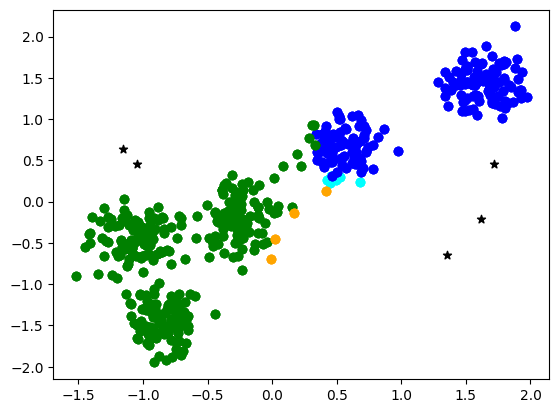

In [31]:
assignPtsToCluster(X,centroids)
plotClusters(centroids)

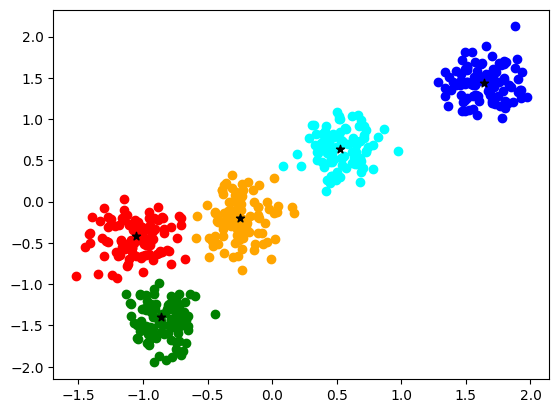

In [36]:
assignPtsToCluster(X,centroids)
plotClusters(centroids)
updatedClusters(centroids)#After 3-4 Refreshes completes our aim